# 2. Logistic regression and k-NN

**FEE308 Data Mining, group NonRefundable.** Author: Mikhail Savushkin.

This notebook tunes and compares two models on the **training set only**: logistic regression and k-nearest
neighbours, each next to a dummy baseline. The test set is loaded together with train (the split is fixed in
`src/preprocessing.py`) but is not used here. It is evaluated once, at the end of the project.

Setup, the same for every model:

- all preprocessing (imputation, rare-category grouping, one-hot, scaling) lives inside one `Pipeline`, so in
  cross-validation it is fitted on the training folds only;
- stratified 5-fold CV with a fixed seed, the same folds for every model;
- hyperparameters are picked with `GridSearchCV` by **PR-AUC**;
- every metric is reported as mean ± std over the 5 folds.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, make_scorer, precision_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))
from preprocessing import RANDOM_STATE, get_X_y, load_train_test, make_pipeline

FIG_DIR = ROOT / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Data and folds

In [2]:
train, _ = load_train_test()  # test set is not used in this notebook
X, y = get_X_y(train)
print(f"train: {X.shape[0]:,} rows, {X.shape[1]} columns, cancelled {y.mean():.1%}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

train: 95,367 rows, 24 columns, cancelled 37.1%


## 2. Metrics

- **PR-AUC** (average precision) is the main metric. It looks at the cancelled class only and does not depend on a
  threshold. A random model scores about 0.37 here, the share of cancellations.
- **F1 for the cancelled class** is the second main metric. It needs a threshold, and here it is the default 0.5.
  Choosing a better threshold (from out-of-fold predictions on train) is done later, so F1 in this notebook is not
  yet the final value.
- **ROC-AUC** is reported because it is common, but with imbalanced classes it looks better than PR-AUC.
- **Recall** shows how many real cancellations the hotel would catch. Precision is added to explain F1.

`zero_division=0` is set so that a model that never predicts "cancelled" gets F1 = 0 without a warning.

In [3]:
SCORING = {
    "pr_auc": "average_precision",
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "recall": "recall",
    "precision": make_scorer(precision_score, zero_division=0),
}
METRICS = list(SCORING)

rows = []


def add_row(name, params, means, stds):
    row = {"model": name, "params": params}
    for m in METRICS:
        row[m] = f"{means[m]:.3f} ± {stds[m]:.3f}"
        row[m + "_mean"] = means[m]
    rows.append(row)


def from_search(name, search):
    res, i = search.cv_results_, search.best_index_
    add_row(name, str(search.best_params_),
            {m: res[f"mean_test_{m}"][i] for m in METRICS},
            {m: res[f"std_test_{m}"][i] for m in METRICS})


def grid_table(search):
    res = pd.DataFrame(search.cv_results_)
    cols = [c for c in res if c.startswith("param_")]
    out = res[cols].rename(columns=lambda c: c.replace("param_model__", ""))
    for m in ["pr_auc", "f1", "recall"]:
        out[m] = res[f"mean_test_{m}"].round(3).astype(str) + " ± " + res[f"std_test_{m}"].round(3).astype(str)
    out["fit_time_s"] = res["mean_fit_time"].round(1)
    out["score_time_s"] = res["mean_score_time"].round(1)
    return out.sort_values("pr_auc", ascending=False)

## 3. Baseline

Two dummy models that ignore the features:

- `prior` always outputs the class share (37%) as the probability, so it never predicts "cancelled" at 0.5;
- `stratified` predicts "cancelled" at random 37% of the time.

Any real model has to be clearly above both.

In [4]:
for strategy in ["prior", "stratified"]:
    dummy = make_pipeline(DummyClassifier(strategy=strategy, random_state=RANDOM_STATE), X)
    res = cross_validate(dummy, X, y, cv=cv, scoring=SCORING)
    add_row(f"dummy ({strategy})", "-",
            {m: res[f"test_{m}"].mean() for m in METRICS},
            {m: res[f"test_{m}"].std() for m in METRICS})

pd.DataFrame(rows)[["model"] + METRICS]

,model,pr_auc,f1,roc_auc,recall,precision
0,dummy (prior),0.371 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
1,dummy (stratified),0.371 ± 0.001,0.369 ± 0.004,0.500 ± 0.003,0.367 ± 0.004,0.371 ± 0.004


## 4. Logistic regression

A linear model on the scaled and one-hot encoded features. Two settings are tuned:

- `C`, the inverse of regularisation strength: small `C` keeps the weights small (simpler model);
- `class_weight`: `"balanced"` gives cancelled bookings a higher weight in the loss, so the model predicts
  "cancelled" more often. This mainly shifts the predicted probabilities, so we expect it to change recall and
  F1 at 0.5 much more than PR-AUC.

In [5]:
logreg = make_pipeline(LogisticRegression(max_iter=3000), X)
logreg_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [None, "balanced"],
}
logreg_search = GridSearchCV(logreg, logreg_grid, cv=cv, scoring=SCORING, refit="pr_auc", n_jobs=-1)
logreg_search.fit(X, y)
from_search("logistic regression", logreg_search)
grid_table(logreg_search)

,C,class_weight,pr_auc,f1,recall,fit_time_s,score_time_s
2,0.10,NaN,0.858 ± 0.002,0.733 ± 0.003,0.674 ± 0.005,0.8,0.2
4,1.00,NaN,0.858 ± 0.002,0.734 ± 0.003,0.675 ± 0.005,1.2,0.2
6,10.00,NaN,0.858 ± 0.002,0.734 ± 0.004,0.675 ± 0.005,1.5,0.1
0,0.01,NaN,0.857 ± 0.002,0.731 ± 0.003,0.665 ± 0.004,1.1,0.2
1,0.01,balanced,0.856 ± 0.002,0.758 ± 0.002,0.792 ± 0.005,1.1,0.1
3,0.10,balanced,0.856 ± 0.002,0.76 ± 0.002,0.797 ± 0.005,1.1,0.2
5,1.00,balanced,0.856 ± 0.002,0.761 ± 0.002,0.798 ± 0.005,1.3,0.1
7,10.00,balanced,0.856 ± 0.002,0.761 ± 0.002,0.798 ± 0.005,1.2,0.1


`C` hardly matters: every value from 0.1 to 10 gives PR-AUC 0.858, and even strong regularisation (`C=0.01`)
loses only 0.001. With 95k rows and about 90 features the model has little room to overfit.

`class_weight="balanced"` does what we expected. PR-AUC stays the same, because the ranking of bookings barely
changes, but at the 0.5 threshold recall goes up from 0.675 to 0.798 and F1 from 0.734 to 0.761. So balancing works
mostly like moving the threshold. The threshold is tuned separately later, so we keep the model chosen by PR-AUC
(`C=10`, no class weights; `C=0.1` or `C=1` would be equally good).

### What the model learned

Because the numeric features are standardised, a coefficient is the change in log-odds of cancelling for one
standard deviation of the feature (or for being in that category). Positive means more likely to cancel.

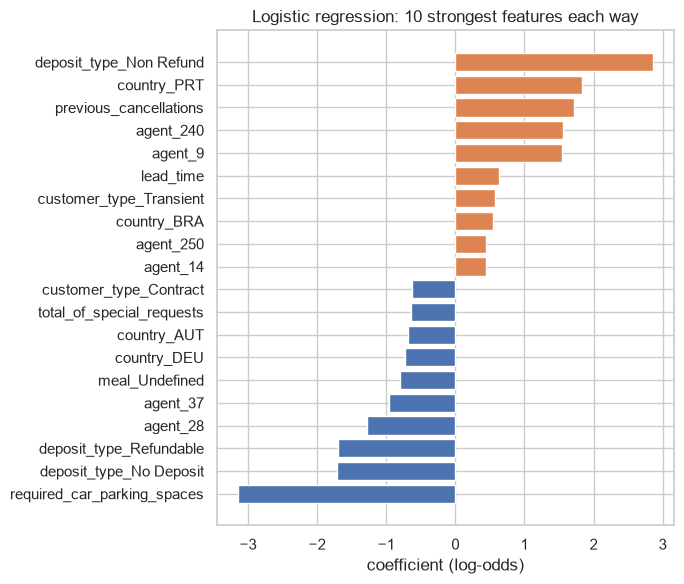

In [6]:
best_logreg = logreg_search.best_estimator_
coefs = pd.Series(best_logreg["model"].coef_[0], index=best_logreg["prep"].get_feature_names_out())
coefs.index = coefs.index.str.split("__").str[1]
top = pd.concat([coefs.nlargest(10), coefs.nsmallest(10)]).sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "#DD8452", "#4C72B0"))
ax.set_xlabel("coefficient (log-odds)")
ax.set_title("Logistic regression: 10 strongest features each way")
fig.tight_layout()
save(fig, "logreg_coefficients")

- The strongest push towards cancelling is a **Non Refund** deposit, as in the EDA, followed by previous
  cancellations and a long lead time.
- Two of the strongest weights belong to the suspicious columns: a **parking space** (the largest weight of all,
  towards staying) and **country = PRT** (towards cancelling). If these fields are filled in at check-in, part of
  the model's skill is leakage. The run without these columns will show how much.
- Several travel agents (9 and 240 up, 28 and 37 down) carry a lot of weight. The IDs are anonymised, so we cannot
  explain them, but it means the model partly learns the habits of specific agents, which can change over time.
- All categories of a column are kept in the one-hot encoding, so the weights inside one column share the effect
  (e.g. "No Deposit" and "Refundable" are both negative mainly because "Non Refund" is strongly positive). They
  show directions, not exact effect sizes.

## 5. k-nearest neighbours

k-NN predicts from the labels of the `k` most similar training bookings (Euclidean distance on the scaled
features). It has no `class_weight` option. Tuned settings:

- `n_neighbors`: small `k` follows the training data closely (high variance), large `k` smooths more;
- `weights`: `"uniform"` gives every neighbour one vote, `"distance"` lets closer neighbours count more.

k-NN does almost nothing during fitting and all the work at prediction time, so this grid is the slowest part.

In [7]:
knn = make_pipeline(KNeighborsClassifier(), X)
knn_grid = {
    "model__n_neighbors": [5, 15, 31, 51, 101],
    "model__weights": ["uniform", "distance"],
}
knn_search = GridSearchCV(knn, knn_grid, cv=cv, scoring=SCORING, refit="pr_auc", n_jobs=-1)
knn_search.fit(X, y)
from_search("k-NN", knn_search)
grid_table(knn_search)

,n_neighbors,weights,pr_auc,f1,recall,fit_time_s,score_time_s
5,31,distance,0.911 ± 0.003,0.807 ± 0.003,0.774 ± 0.004,0.4,18.8
7,51,distance,0.911 ± 0.003,0.806 ± 0.003,0.768 ± 0.004,0.4,19.6
9,101,distance,0.91 ± 0.003,0.804 ± 0.003,0.76 ± 0.004,0.4,20.7
3,15,distance,0.907 ± 0.003,0.805 ± 0.002,0.778 ± 0.004,0.4,18.8
4,31,uniform,0.875 ± 0.002,0.766 ± 0.003,0.721 ± 0.003,0.4,19.3
1,5,distance,0.874 ± 0.002,0.794 ± 0.003,0.783 ± 0.004,0.3,17.1
2,15,uniform,0.873 ± 0.002,0.775 ± 0.004,0.738 ± 0.005,0.4,17.5
6,51,uniform,0.873 ± 0.002,0.76 ± 0.003,0.711 ± 0.003,0.4,20.7
8,101,uniform,0.869 ± 0.002,0.753 ± 0.004,0.697 ± 0.004,0.4,21.8
0,5,uniform,0.84 ± 0.002,0.777 ± 0.002,0.759 ± 0.005,0.2,18.5


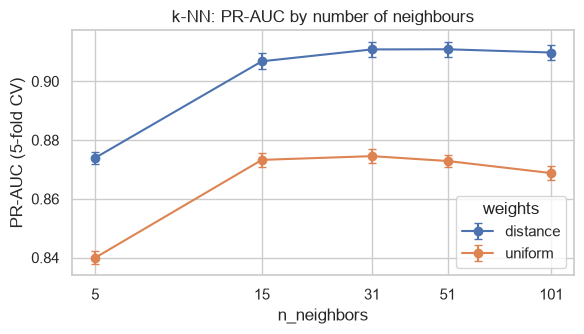

In [8]:
res = pd.DataFrame(knn_search.cv_results_)
fig, ax = plt.subplots(figsize=(6, 3.5))
for w, part in res.groupby("param_model__weights"):
    ax.errorbar(part["param_model__n_neighbors"].astype(int), part["mean_test_pr_auc"],
                yerr=part["std_test_pr_auc"], marker="o", capsize=3, label=w)
ax.set_xscale("log")
ax.set_xticks([5, 15, 31, 51, 101], labels=["5", "15", "31", "51", "101"])
ax.set_xlabel("n_neighbors")
ax.set_ylabel("PR-AUC (5-fold CV)")
ax.legend(title="weights")
ax.set_title("k-NN: PR-AUC by number of neighbours")
fig.tight_layout()
save(fig, "knn_pr_auc")

- Small `k` overfits: `k=5` is the worst setting for both weightings. From `k=15` on the curve is almost flat. The best
  setting is `k=51` with distance weights (PR-AUC 0.911), with `k=31` equally good.
- `distance` beats `uniform` by about 0.035 PR-AUC at every `k`. This is a large gap for such a small change, so we
  checked where it comes from.

In [9]:
# first CV fold: does a validation row have an identical feature row in the training part?
tr, va = next(cv.split(X, y))
key = pd.util.hash_pandas_object(X.astype(str), index=False)
twin_rate = y.iloc[tr].groupby(key.iloc[tr].values).mean()
has_twin = key.iloc[va].isin(twin_rate.index).values
y_va = y.iloc[va][has_twin].values
twin_label = twin_rate[key.iloc[va][has_twin]].round().values

print(f"validation rows with an identical row in the training folds: {has_twin.mean():.1%}")
print(f"same label as the copy in train: {(twin_label == y_va).mean():.1%}")
print(f"cancellation rate: rows with a copy {y_va.mean():.1%}, without {y.iloc[va][~has_twin].mean():.1%}")

validation rows with an identical row in the training folds: 32.3%
same label as the copy in train: 98.2%
cancellation rate: rows with a copy 59.4%, without 26.4%


About a third of the validation rows have an exact copy in the training folds, and the copy has the same label
in 98% of cases. With `weights="distance"`, a neighbour at distance 0 gets almost all the weight, so k-NN simply
returns the label of the copy. This is the duplicate problem from EDA section 5: the copies are most likely parts of
the same group booking, which is cancelled or kept as a whole.

For a really new booking there is no copy in the training data, so the k-NN score here is too optimistic. The
grouped split (identical rows always in the same fold) will measure by how much.

## 6. Comparison

In [10]:
results = pd.DataFrame(rows)
results[["model", "params"] + METRICS]

,model,params,pr_auc,f1,roc_auc,recall,precision
0,dummy (prior),-,0.371 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
1,dummy (stratified),-,0.371 ± 0.001,0.369 ± 0.004,0.500 ± 0.003,0.367 ± 0.004,0.371 ± 0.004
2,logistic regression,"{'model__C': 10, 'model__class_weight': None}",0.858 ± 0.002,0.734 ± 0.004,0.901 ± 0.002,0.675 ± 0.005,0.804 ± 0.003
3,k-NN,"{'model__n_neighbors': 51, 'model__weights': 'distance'}",0.911 ± 0.003,0.806 ± 0.003,0.935 ± 0.001,0.768 ± 0.004,0.848 ± 0.004


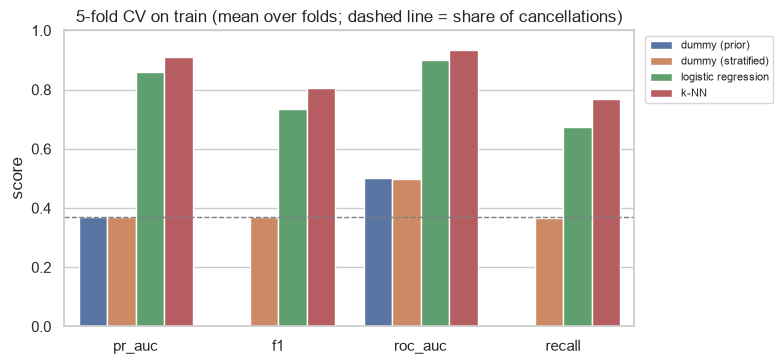

In [11]:
plot_df = results.melt(id_vars="model", value_vars=[m + "_mean" for m in ["pr_auc", "f1", "roc_auc", "recall"]],
                       var_name="metric", value_name="score")
plot_df["metric"] = plot_df["metric"].str.replace("_mean", "")

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(plot_df, x="metric", y="score", hue="model", ax=ax)
ax.axhline(y.mean(), color="grey", ls="--", lw=1)
ax.set_ylim(0, 1)
ax.set_xlabel("")
ax.set_title("5-fold CV on train (mean over folds; dashed line = share of cancellations)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
fig.tight_layout()
save(fig, "cv_comparison_logreg_knn")

## 7. Summary

- Both models are far above the dummy baseline (PR-AUC 0.37). In cross-validation they already pass the targets
  from the proposal (PR-AUC ≥ 0.70, F1 ≥ 0.65), even at the default threshold of 0.5.
- **k-NN** is best on every metric: PR-AUC 0.911 ± 0.003, F1 0.806 ± 0.003. **Logistic regression** is second:
  PR-AUC 0.858 ± 0.002, F1 0.734 ± 0.004. The std over folds is at most 0.005 for every model, so the gap between
  the two models is much larger than the fold-to-fold noise.
- We do not trust these numbers yet. k-NN's lead probably comes partly from duplicate bookings, and logistic
  regression leans heavily on the parking and country columns. Two extra checks follow:
  1. the same models without `booking_changes`, `days_in_waiting_list`, `required_car_parking_spaces`, `country`;
  2. a grouped split where identical rows stay in the same fold.
- What did not help: tuning `C` (all values within 0.001 PR-AUC), `class_weight` for PR-AUC, `uniform` weights and
  small `k` for k-NN.
- Cost: k-NN needs about 20 s to score one validation fold of 19k bookings, logistic regression less than 0.2 s.

The decision threshold (from out-of-fold predictions on train) and the single test-set evaluation come later.